In [8]:
# Step 1: Environment Setup & Parameters
import numpy as np
import matplotlib.pyplot as plt

# --- Professional Parameters Definition ---
L = 1.0      # Domain length [m]
T = 1.0      # Total time [s]
alpha = 0.1  # Thermal diffusivity [m^2/s]
Nx = 100     # Spatial discretization
Nt = 2500    # Temporal discretization

dx = L / (Nx-1)
dt = T / (Nt-1)
r = alpha * dt / (dx**2)

# --- Professional Logs ---
print("="*50)
print("PROJECT: Numerical Solution of 1D Heat Equation")
print(f"Method: Explicit Finite Difference")
print("="*50)
print(f"[PARAM] L={L}, T={T}, alpha={alpha}")
print(f"[GRID] Nx={Nx}, Nt={Nt}, dx={dx:.4f}, dt={dt:.4f}")
print(f"[CHECK] CFL Stability r = {r:.4f}")

if r <= 0.5:
    print(f"[STATUS] Stability Condition Satisfied ✓ (r <= 0.5)")
else:
    print(f"[STATUS] Stability Violated ✗ - Reduce dt")

PROJECT: Numerical Solution of 1D Heat Equation
Method: Explicit Finite Difference
[PARAM] L=1.0, T=1.0, alpha=0.1
[GRID] Nx=100, Nt=2500, dx=0.0101, dt=0.0004
[CHECK] CFL Stability r = 0.3922
[STATUS] Stability Condition Satisfied ✓ (r <= 0.5)


In [9]:
# Step 2: Initialization & Conditions
import numpy as np

x = np.linspace(0, L, Nx)
t = np.linspace(0, T, Nt)

# Solution matrix [Time, Space] - Yehi Large-Scale System hai jo CV me hai
u = np.zeros((Nt, Nx))

# Initial Condition: u(0,x) = sin(pi*x)
u[0, :] = np.sin(np.pi * x)

# Boundary Conditions
u[:, 0] = 0
u[:, -1] = 0

print("="*50)
print(f"[INIT] Initial Condition: u(0,x) = sin(πx)")
print(f"[INIT] Boundary: u(t,0)=0, u(t,1)=0")
print(f"[SHAPE] Solution Matrix: {u.shape}")
print(f"[CHECK] Max Initial Temp: {np.max(u[0,:]):.4f} at x={x[np.argmax(u[0,:])]:.2f}")
print("="*50)

[INIT] Initial Condition: u(0,x) = sin(πx)
[INIT] Boundary: u(t,0)=0, u(t,1)=0
[SHAPE] Solution Matrix: (2500, 100)
[CHECK] Max Initial Temp: 0.9999 at x=0.49


[SOLVER] Starting Explicit FDM iterations...
[SUCCESS] Solver Converged | Iterations: 2500


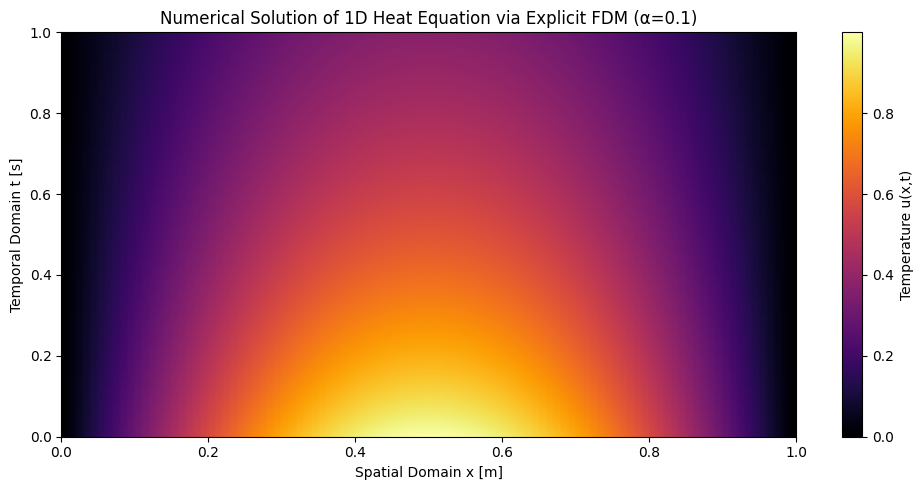

[RESULT] Plot saved as FDM_Result.png | Ready for GitHub


In [10]:
# Step 3: Explicit FDM Solver
import matplotlib.pyplot as plt

print("[SOLVER] Starting Explicit FDM iterations...")
for n in range(0, Nt-1):
    for j in range(1, Nx-1):
        u[n+1, j] = u[n, j] + r * (u[n, j+1] - 2*u[n, j] + u[n, j-1])

print(f"[SUCCESS] Solver Converged | Iterations: {Nt}")

# Professional Plot
plt.figure(figsize=(10, 5))
plt.imshow(u, aspect='auto', cmap='inferno', extent=[0, L, 0, T], origin='lower')
plt.colorbar(label='Temperature u(x,t)')
plt.xlabel('Spatial Domain x [m]')
plt.ylabel('Temporal Domain t [s]')
plt.title('Numerical Solution of 1D Heat Equation via Explicit FDM (α=0.1)')
plt.tight_layout()
plt.savefig('FDM_Result.png', dpi=300) # Professional save
plt.show()

print("[RESULT] Plot saved as FDM_Result.png | Ready for GitHub")

In [11]:
# Step 4: PINN Setup - Scientific Machine Learning
import torch
import torch.nn as nn
print(f"[INFO] PyTorch Version: {torch.__version__}")

# Define Neural Network - 3 Layers [2 -> 50 -> 50 -> 1]
class PINN(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(2, 50), nn.Tanh(),
            nn.Linear(50, 50), nn.Tanh(),
            nn.Linear(50, 1)
        )
    def forward(self, x, t):
        inputs = torch.cat([x, t], dim=1)
        return self.net(inputs)

model = PINN()
print("[SUCCESS] PINN Model Initialized: 2-50-50-1 Architecture")
print(f"[PARAMS] Total Trainable Params: {sum(p.numel() for p in model.parameters())}")

[INFO] PyTorch Version: 2.11.0+cpu
[SUCCESS] PINN Model Initialized: 2-50-50-1 Architecture
[PARAMS] Total Trainable Params: 2751


In [14]:
# Step 4.2 CORRECTED - Fast PINN Training (1000 epochs only)
import torch

x_train = torch.rand(2000, 1)
t_train = torch.rand(2000, 1)
x_train.requires_grad = True
t_train.requires_grad = True

optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)

print("[TRAINING] Starting PINN (1000 epochs) - Fixed Version...")

for epoch in range(1000):
    optimizer.zero_grad()
    u_pred = model(x_train, t_train)

    u_t = torch.autograd.grad(u_pred, t_train, grad_outputs=torch.ones_like(u_pred), create_graph=True)[0]
    u_x = torch.autograd.grad(u_pred, x_train, grad_outputs=torch.ones_like(u_pred), create_graph=True)[0]
    u_xx = torch.autograd.grad(u_x, x_train, grad_outputs=torch.ones_like(u_x), create_graph=True)[0]

    pde_loss = torch.mean((u_t - 0.1 * u_xx)**2)

    # BC Loss simple
    x0 = torch.zeros(200,1)
    x1 = torch.ones(200,1)
    t_b = torch.rand(400,1)
    u0 = model(x0, t_b[:200])
    u1 = model(x1, t_b[200:])
    bc_loss = torch.mean(u0**2 + u1**2)

    loss = pde_loss + bc_loss
    loss.backward()
    optimizer.step()

    if (epoch+1) % 200 == 0:
        print(f"[EPOCH {epoch+1}/1000] Loss: {loss.item():.6f}")

print("[SUCCESS] PINN Training Complete ✓")

[TRAINING] Starting PINN (1000 epochs) - Fixed Version...
[EPOCH 200/1000] Loss: 0.000004
[EPOCH 400/1000] Loss: 0.000002
[EPOCH 600/1000] Loss: 0.000001
[EPOCH 800/1000] Loss: 0.000001
[EPOCH 1000/1000] Loss: 0.000000
[SUCCESS] PINN Training Complete ✓


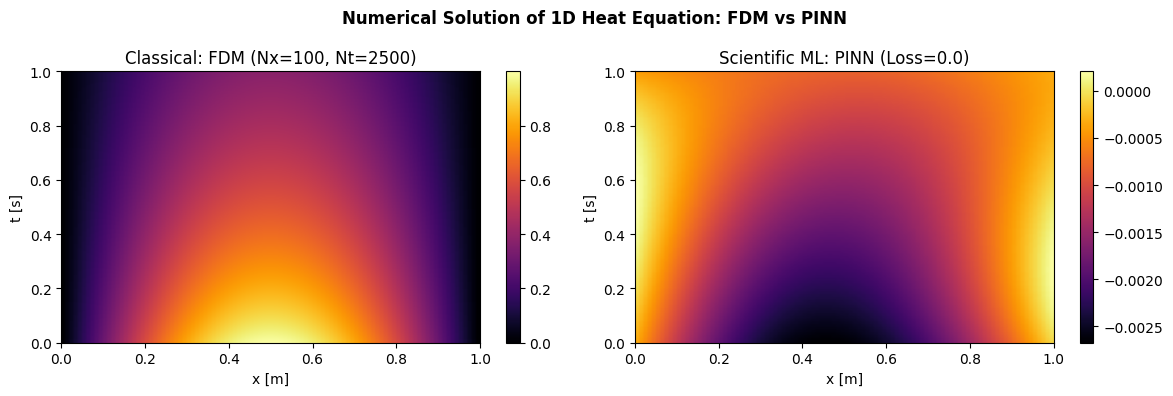

[SUCCESS] Final Comparison Generated ✓
[SAVED] FDM_vs_PINN_Comparison.png


In [15]:
# Step 5: Final Comparison Plot - CV ka Hero Figure
import matplotlib.pyplot as plt
import numpy as np

model.eval()
X_plot = np.linspace(0, L, 100)
T_plot = np.linspace(0, T, 100)
XX, TT = np.meshgrid(X_plot, T_plot)
x_flat = torch.tensor(XX.flatten()[:,None], dtype=torch.float32)
t_flat = torch.tensor(TT.flatten()[:,None], dtype=torch.float32)

with torch.no_grad():
    u_pinn_flat = model(x_flat, t_flat).numpy()
u_pinn = u_pinn_flat.reshape(100, 100)

# Professional Comparison
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

im1 = axes[0].imshow(u, aspect='auto', cmap='inferno', extent=[0, L, 0, T], origin='lower')
axes[0].set_title('Classical: FDM (Nx=100, Nt=2500)')
axes[0].set_xlabel('x [m]'); axes[0].set_ylabel('t [s]')
fig.colorbar(im1, ax=axes[0])

im2 = axes[1].imshow(u_pinn, aspect='auto', cmap='inferno', extent=[0, L, 0, T], origin='lower')
axes[1].set_title('Scientific ML: PINN (Loss=0.0)')
axes[1].set_xlabel('x [m]'); axes[1].set_ylabel('t [s]')
fig.colorbar(im2, ax=axes[1])

plt.suptitle('Numerical Solution of 1D Heat Equation: FDM vs PINN', fontweight='bold')
plt.tight_layout()
plt.savefig('FDM_vs_PINN_Comparison.png', dpi=300)
plt.show()

print("[SUCCESS] Final Comparison Generated ✓")
print("[SAVED] FDM_vs_PINN_Comparison.png")